# Project 3 - Step 1: 3D Topology Optimization with Hexahedron (Hex8) Elements

This notebook extends my **Project 2 (2D, Q4 elements)** code to **3D (Hex8 elements)**.
The method is the same: **SIMP** penalization + **sensitivity filter** + **Optimality Criteria (OC)** update.

Test problem: **cantilever beam**. The left face (x = 0) is fixed and a downward load is applied
along the line at the middle of the right face (x = L, y = H/2), like the 2D problem.

Sections follow the same order as my 2D notebook:
1. Import libraries  2. Mesh (generated, instead of reading node.txt / element.txt)
3. Volume and center of elements  4. FEA code  5. Boundary conditions
6. Topology optimization  7. Plotting  8. Tests

In [1]:
#####################
# 1. Import Libraries
#####################
import os
import time

import numpy as np
import matplotlib.pyplot as plt
from scipy.sparse import coo_matrix
from scipy.sparse.linalg import spsolve
from scipy.spatial import cKDTree

RESULTS_DIR = "step1_results"
os.makedirs(RESULTS_DIR, exist_ok=True)

# Material properties, used everywhere below (same values as my Project 2 code)
E0 = 1.0    # Young's modulus
NU = 0.25   # Poisson's ratio

In [2]:
############################################################
# 2. Mesh generation (2D: read from node.txt / element.txt)
############################################################
def generate_mesh(nelx, nely, nelz, lx, ly, lz):
    """Structured hexahedron mesh of a box lx * ly * lz.

    Returns node_list (n_node, 3) and element_list (n_elem, 8) with 1-based
    node IDs, the same convention as the 2D input files.
    Node numbering: x runs fastest, then y, then z (2D: x fastest, then y).
    """
    dx, dy, dz = lx / nelx, ly / nely, lz / nelz
    nx, ny = nelx + 1, nely + 1

    k, j, i = np.meshgrid(np.arange(nelz + 1), np.arange(ny), np.arange(nx), indexing="ij")
    node_list = np.column_stack([i.ravel() * dx, j.ravel() * dy, k.ravel() * dz])

    def node_id(i, j, k):
        return i + j * nx + k * nx * ny + 1

    ez, ey, ex = np.meshgrid(np.arange(nelz), np.arange(nely), np.arange(nelx), indexing="ij")
    ex, ey, ez = ex.ravel(), ey.ravel(), ez.ravel()
    # bottom face (z) counter-clockwise, then top face (z + dz) counter-clockwise
    element_list = np.column_stack([
        node_id(ex, ey, ez),         node_id(ex + 1, ey, ez),
        node_id(ex + 1, ey + 1, ez), node_id(ex, ey + 1, ez),
        node_id(ex, ey, ez + 1),     node_id(ex + 1, ey, ez + 1),
        node_id(ex + 1, ey + 1, ez + 1), node_id(ex, ey + 1, ez + 1),
    ])
    return node_list, element_list

In [3]:
##############################################################
# 3. Volume and center of elements (2D: area and center)
##############################################################
def volume_center(node_list, element_list):
    xyz = node_list[element_list - 1]          # (n_elem, 8, 3)
    center = xyz.mean(axis=1)
    # elements are axis-aligned boxes (voxels), so volume = dx * dy * dz
    volume = np.prod(xyz.max(axis=1) - xyz.min(axis=1), axis=1)
    return volume, center

In [4]:
##############
# 4. FEA Code
##############
# (a) Natural coordinates of the 8 nodes and the 2x2x2 Gauss points
#     (2D: 4 nodes, 2x2 Gauss points)
NODE_SIGNS = np.array([[-1, -1, -1], [1, -1, -1], [1, 1, -1], [-1, 1, -1],
                       [-1, -1,  1], [1, -1,  1], [1, 1,  1], [-1, 1,  1]])
g = 1 / np.sqrt(3)
GAUSS_POINTS = np.array([[a, b, c] for c in (-g, g) for b in (-g, g) for a in (-g, g)])


def dN_natural(xi, eta, zeta):
    # N_i = 1/8 (1 + xi*xi_i)(1 + eta*eta_i)(1 + zeta*zeta_i); returns dN/d(xi, eta, zeta), shape (3, 8)
    s = NODE_SIGNS
    dN = np.zeros((3, 8))
    dN[0] = s[:, 0] * (1 + eta * s[:, 1]) * (1 + zeta * s[:, 2]) / 8
    dN[1] = s[:, 1] * (1 + xi * s[:, 0]) * (1 + zeta * s[:, 2]) / 8
    dN[2] = s[:, 2] * (1 + xi * s[:, 0]) * (1 + eta * s[:, 1]) / 8
    return dN

In [5]:
# (b) B matrix: 6 x 24 (2D: 3 x 8)
#     strain order: [eps_xx, eps_yy, eps_zz, gamma_xy, gamma_yz, gamma_zx]
def B_matrix(xi, eta, zeta, xyz):
    dN = dN_natural(xi, eta, zeta)
    J = dN @ xyz                       # Jacobian, J[a, b] = d x_b / d xi_a
    dNdx = np.linalg.solve(J, dN)      # derivatives w.r.t. x, y, z
    B = np.zeros((6, 24))
    B[0, 0::3] = dNdx[0]
    B[1, 1::3] = dNdx[1]
    B[2, 2::3] = dNdx[2]
    B[3, 0::3] = dNdx[1]; B[3, 1::3] = dNdx[0]
    B[4, 1::3] = dNdx[2]; B[4, 2::3] = dNdx[1]
    B[5, 0::3] = dNdx[2]; B[5, 2::3] = dNdx[0]
    return B, np.linalg.det(J)

In [6]:
# (c) D matrix: 6 x 6 isotropic 3D elasticity (2D: 3 x 3 plane stress)
def D_matrix(E, v):
    lam = E * v / ((1 + v) * (1 - 2 * v))
    mu = E / (2 * (1 + v))
    D = np.zeros((6, 6))
    D[:3, :3] = lam
    D[:3, :3] += 2 * mu * np.eye(3)
    D[3:, 3:] = mu * np.eye(3)
    return D

In [7]:
# (d) Element stiffness matrix: 24 x 24 (2D: 8 x 8)
#     In 2D the Jacobian cancelled for square elements, so it was left out.
#     In 3D it does NOT cancel (k_e scales with the element size), so det(J) is included.
def stiffness_matrix(E, v, xyz):
    D = D_matrix(E, v)
    ke = np.zeros((24, 24))
    for xi, eta, zeta in GAUSS_POINTS:
        B, detJ = B_matrix(xi, eta, zeta, xyz)
        ke += B.T @ D @ B * detJ        # Gauss weights are all 1
    return ke

In [8]:
# (e) Element DOFs and sparse global stiffness matrix
#     node n (1-based) has DOFs 3n-3 (x), 3n-2 (y), 3n-1 (z)   (2D: 2n-2, 2n-1)
def element_dofs(element_list):
    edof = np.empty((element_list.shape[0], 24), dtype=int)
    edof[:, 0::3] = element_list * 3 - 3
    edof[:, 1::3] = element_list * 3 - 2
    edof[:, 2::3] = element_list * 3 - 1
    return edof


def global_stiffness_matrix(n_dof, edof, x, penal, ke):
    # 2D used a dense matrix and a double for-loop. In 3D the matrix is too big for that,
    # so all (row, col, value) triplets are built at once and summed into a sparse matrix.
    rows = np.repeat(edof, 24, axis=1).ravel()
    cols = np.tile(edof, (1, 24)).ravel()
    vals = (x[:, None] ** penal * ke.ravel()[None, :]).ravel()
    return coo_matrix((vals, (rows, cols)), shape=(n_dof, n_dof)).tocsc()


def solve_FE(K, f, fixed_dof):
    n_dof = K.shape[0]
    free_dof = np.setdiff1d(np.arange(n_dof), fixed_dof)
    u = np.zeros(n_dof)
    u[free_dof] = spsolve(K[free_dof][:, free_dof], f[free_dof])   # 2D: np.linalg.solve
    return u

In [9]:
###############################################
# 5. Boundary conditions (2D: fixed.txt, force.txt)
###############################################
def cantilever_bcs(node_list, lx, ly, F=-1.0):
    """Fix all DOFs on the face x = 0. Total load F (in y) spread over the
    nodes on the line x = lx, y = ly/2 (the middle of the right face)."""
    n_dof = node_list.shape[0] * 3
    tol = 1e-9
    fixed_node = np.where(np.abs(node_list[:, 0]) < tol)[0] + 1
    force_node = np.where((np.abs(node_list[:, 0] - lx) < tol) &
                          (np.abs(node_list[:, 1] - ly / 2) < tol))[0] + 1

    if len(force_node) == 0:
        raise ValueError("No nodes on the load line y = ly/2: use an even number of elements in y (nely)")

    fixed_dof = np.concatenate([fixed_node * 3 - 3, fixed_node * 3 - 2, fixed_node * 3 - 1])
    f = np.zeros(n_dof)
    f[force_node * 3 - 2] = F / len(force_node)
    return f, fixed_dof, fixed_node, force_node


def project2_bcs(node_list, lx, ly, F=1.0):
    """The boundary conditions my 2D Project 2 code actually uses (from the class template):
    left face fixed in x only (rollers), y fixed at the bottom node x = 50 (node 21 in 2D:
    fixed_dof = fixed_node*2-2 plus [[21*2-1]]), load +F in y at the middle of the right face.
    In 3D, z is also fixed on the left face to stop the slab from moving in z."""
    n_dof = node_list.shape[0] * 3
    tol = 1e-9
    left = np.where(np.abs(node_list[:, 0]) < tol)[0] + 1
    pin = np.where((np.abs(node_list[:, 0] - 50) < tol) & (np.abs(node_list[:, 1]) < tol))[0] + 1
    force_node = np.where((np.abs(node_list[:, 0] - lx) < tol) &
                          (np.abs(node_list[:, 1] - ly / 2) < tol))[0] + 1
    fixed_dof = np.concatenate([left * 3 - 3, left * 3 - 1, pin * 3 - 2])
    f = np.zeros(n_dof)
    f[force_node * 3 - 2] = F / len(force_node)
    return f, fixed_dof, left, force_node

In [10]:
##########################
# 6. Topology Optimization
##########################
# (a) Sensitivity filter (same formula as 2D, neighbours inside a SPHERE instead of a circle).
#     The 2D code looped over all element pairs (n^2). With thousands of 3D elements that is
#     too slow, so a KD-tree finds the neighbours once and the weights are stored sparsely.
def filter_weights(center, rmin):
    tree = cKDTree(center)
    neighbours = tree.query_ball_point(center, r=rmin)
    rows = np.repeat(np.arange(len(center)), [len(n) for n in neighbours])
    cols = np.concatenate(neighbours)
    w = rmin - np.linalg.norm(center[rows] - center[cols], axis=1)
    keep = w > 0
    H = coo_matrix((w[keep], (rows[keep], cols[keep])), shape=(len(center),) * 2).tocsr()
    Hs = np.asarray(H.sum(axis=1)).ravel()
    return H, Hs


def mesh_independency(H, Hs, x, dc):
    # dc_i = sum_j H_ij x_j dc_j / (x_i sum_j H_ij)
    return (H @ (x * dc)) / (np.maximum(1e-3, x) * Hs)

In [11]:
# (b) Optimality Criteria update (unchanged from 2D, area -> volume)
def optimality_criteria(volume, x, volfrac, dc, move=0.2, x_min=1e-3):
    target = volfrac * volume.sum()
    l1, l2 = 0.0, 1e9
    while (l2 - l1) / (l2 + l1) > 1e-4:
        lmid = 0.5 * (l1 + l2)
        x_new = np.clip(x * np.sqrt(np.maximum(-dc, 1e-10) / lmid),
                        np.maximum(x_min, x - move),
                        np.minimum(1.0, x + move))
        if volume @ x_new > target:
            l1 = lmid
        else:
            l2 = lmid
    return x_new

In [12]:
# (c) Main TO driver
def run_TO3D(nelx, nely, nelz, lx, ly, lz, volfrac=0.3, penal=3.0, rmin=1.5,
             E=E0, v=NU, tol=0.01, loop_max=100, print_every=5, bcs=cantilever_bcs):
    node_list, element_list = generate_mesh(nelx, nely, nelz, lx, ly, lz)
    volume, center = volume_center(node_list, element_list)
    edof = element_dofs(element_list)
    n_dof = node_list.shape[0] * 3
    ke = stiffness_matrix(E, v, node_list[element_list[0] - 1])   # all elements are identical
    H, Hs = filter_weights(center, rmin)
    f, fixed_dof, _, _ = bcs(node_list, lx, ly)

    print(f"Mesh {nelx} x {nely} x {nelz}: {element_list.shape[0]} elements, {n_dof} DOFs")
    x = np.full(element_list.shape[0], volfrac)
    history = {"c": [], "vol": [], "change": []}
    change, loop = 1.0, 0
    t0 = time.time()

    while change > tol and loop < loop_max:
        loop += 1
        x_old = x.copy()

        # FE analysis
        K = global_stiffness_matrix(n_dof, edof, x, penal, ke)
        u = solve_FE(K, f, fixed_dof)

        # objective function (compliance) and sensitivity
        ue = u[edof]                                   # (n_elem, 24)
        ce = np.einsum("ij,jk,ik->i", ue, ke, ue)      # ue^T ke ue for every element
        c = np.sum(x ** penal * ce)
        dc = -penal * x ** (penal - 1) * ce

        # filter and design update
        dc = mesh_independency(H, Hs, x, dc)
        x = optimality_criteria(volume, x, volfrac, dc)

        change = np.max(np.abs(x - x_old))
        vol = volume @ x / volume.sum()
        history["c"].append(c); history["vol"].append(vol); history["change"].append(change)
        if loop % print_every == 0 or loop == 1:
            print(f"It {loop:3d} | c = {c:10.4f} | vol = {vol:.3f} | change = {change:.4f}")

    status = "converged" if change <= tol else "stopped at loop_max"
    print(f"{status} after {loop} iterations, {time.time() - t0:.1f} s, final c = {c:.4f}")
    mesh = dict(node_list=node_list, element_list=element_list,
                shape=(nelx, nely, nelz), size=(lx, ly, lz))
    return x, history, mesh

In [13]:
#############
# 7. Plotting
#############
def plot_voxels(x, mesh, threshold=0.5, title="", ax=None):
    """3D view: draw elements with density > threshold, shaded by density."""
    nelx, nely, nelz = mesh["shape"]
    lx, ly, lz = mesh["size"]
    dens = x.reshape(nelz, nely, nelx).transpose(2, 1, 0)       # index [ix, iy, iz]
    X, Y, Z = np.meshgrid(np.linspace(0, lx, nelx + 1), np.linspace(0, ly, nely + 1),
                          np.linspace(0, lz, nelz + 1), indexing="ij")
    colors = np.empty(dens.shape + (4,))
    colors[..., :3] = (1 - dens[..., None]) * 0.75     # darker = denser
    colors[..., 3] = 1.0
    if ax is None:
        fig = plt.figure(figsize=(10, 5))
        ax = fig.add_subplot(projection="3d")
    ax.voxels(X, Y, Z, dens > threshold, facecolors=colors, edgecolor="k", linewidth=0.1)
    ax.set_box_aspect((lx, ly, lz))
    ax.set_xlabel("x"); ax.set_ylabel("y"); ax.set_zlabel("z")
    ax.set_title(title)
    return ax


def plot_side_view(x, mesh, title="", ax=None):
    """2D view like Project 2: density averaged through the thickness (z)."""
    nelx, nely, nelz = mesh["shape"]
    lx, ly, _ = mesh["size"]
    dens = x.reshape(nelz, nely, nelx).mean(axis=0)
    if ax is None:
        _, ax = plt.subplots(figsize=(10, 4))
    ax.imshow(1 - dens, cmap="gray", origin="lower", extent=[0, lx, 0, ly], vmin=0, vmax=1)
    ax.set_title(title)
    return ax


def plot_history(history, ax=None):
    if ax is None:
        _, ax = plt.subplots(figsize=(6, 3.5))
    it = np.arange(1, len(history["c"]) + 1)
    ax.plot(it, history["c"], color="#2563eb")
    ax.set_xlabel("Iteration"); ax.set_ylabel("Compliance c", color="#2563eb")
    ax2 = ax.twinx()
    ax2.plot(it, history["vol"], color="#d97706")
    ax2.set_ylabel("Volume fraction", color="#d97706"); ax2.set_ylim(0, 1)
    return ax

## 8. Tests
### Test 1 - Element stiffness matrix checks
A correct Hex8 stiffness matrix must be **symmetric** and have exactly **6 zero eigenvalues**
(3 rigid translations + 3 rigid rotations: the element can move without strain).
All other eigenvalues must be positive. (In 2D: 3 zero eigenvalues.)

In [14]:
unit_cube = (NODE_SIGNS + 1) / 2          # 1 x 1 x 1 element
ke_test = stiffness_matrix(E0, NU, unit_cube)
eig = np.linalg.eigvalsh(ke_test)
print("ke shape:", ke_test.shape)
print("symmetric:", np.allclose(ke_test, ke_test.T))
print("number of ~zero eigenvalues (rigid body modes):", np.sum(np.abs(eig) < 1e-10))
print("smallest non-zero eigenvalue > 0:", eig[6] > 0)

# element size effect: in 3D, k_e doubles when the element size doubles (in 2D it did not change)
ke_2 = stiffness_matrix(E0, NU, unit_cube * 2)
print("ke(size 2) / ke(size 1) =", round(ke_2[0, 0] / ke_test[0, 0], 6))

ke shape: (24, 24)
symmetric: True
number of ~zero eigenvalues (rigid body modes): 6
smallest non-zero eigenvalue > 0: True
ke(size 2) / ke(size 1) = 2.0


### Test 2 - FE solver check against beam theory
Solid cantilever (all densities = 1), L = 60, H = 20, B = 4, E = 1, v = 0.25, total load F = 1.
Timoshenko beam theory: tip deflection = F L^3 / (3 E I) + F L / (kappa G A), kappa = 5/6.
Linear Hex8 elements are known to be too stiff in bending (shear locking), so the FE value
should be a bit **smaller** than theory and get closer when the mesh is refined.

In [15]:
L, Hb, Bb, E, v, F = 60.0, 20.0, 4.0, E0, NU, 1.0
I = Bb * Hb**3 / 12
G = E / (2 * (1 + v))
delta_theory = F * L**3 / (3 * E * I) + F * L / (5 / 6 * G * Bb * Hb)
print(f"Timoshenko beam theory tip deflection: {delta_theory:.3f}")

for nelx, nely, nelz in [(12, 4, 1), (30, 10, 2), (60, 20, 4), (90, 30, 6)]:
    nodes, elems = generate_mesh(nelx, nely, nelz, L, Hb, Bb)
    edof_t = element_dofs(elems)
    ke_t = stiffness_matrix(E, v, nodes[elems[0] - 1])
    K = global_stiffness_matrix(nodes.shape[0] * 3, edof_t, np.ones(len(elems)), 1, ke_t)
    f_t, fixed_t, _, force_t = cantilever_bcs(nodes, L, Hb, F=-F)
    u = solve_FE(K, f_t, fixed_t)
    delta_fe = -u[force_t * 3 - 2].mean()
    print(f"mesh {nelx:2d} x {nely:2d} x {nelz}: FE tip deflection = {delta_fe:.3f} "
          f"({100 * delta_fe / delta_theory:.1f}% of theory)")

Timoshenko beam theory tip deflection: 29.250
mesh 12 x  4 x 1: FE tip deflection = 27.993 (95.7% of theory)
mesh 30 x 10 x 2: FE tip deflection = 29.094 (99.5% of theory)


mesh 60 x 20 x 4: FE tip deflection = 29.364 (100.4% of theory)


mesh 90 x 30 x 6: FE tip deflection = 29.456 (100.7% of theory)


### Test 3 - Does the 3D code reproduce my 2D Project 2 result?
Same problem as Project 2: 100 x 40 domain, 40 x 16 elements (size 2.5), **one element thick**,
volfrac = 0.3, E = 1, v = 0.25, and the **same boundary conditions as my 2D code**
(`project2_bcs`: left edge fixed in x only + y pinned at the bottom node x = 50, load +1 upward).
A one-element-thick slab behaves like the 2D plane-stress model, so the shape should match.

Two parameter sets: my Project 2 values (penal = 5, rmin = 3) and better-behaved values
(penal = 3, rmin = 3.75 = 1.5 elements). With rmin = 3 the filter reaches only 1.2 elements and the
design keeps oscillating (change stays at the move limit 0.2), which is why my 2D run stopped at loop_max.
More iterations do not help: after ~400 iterations it repeats a 4-iteration cycle of almost identical
designs (compliance 37.684 / 37.771 / 37.689 / 37.771, only 0.2 % apart), so the shape is final
but `change` never drops below tol. The right-hand plots show the final shape (density > 0.5).

Mesh 40 x 16 x 1: 640 elements, 4182 DOFs


It   1 | c =  6173.9517 | vol = 0.300 | change = 0.2000


It  50 | c =    40.7596 | vol = 0.300 | change = 0.2000


It 100 | c =    38.1282 | vol = 0.300 | change = 0.1071


It 150 | c =    38.1759 | vol = 0.300 | change = 0.1242


It 200 | c =    38.1588 | vol = 0.300 | change = 0.1232


... (4 outputs left out)

It 450 | c =    37.7716 | vol = 0.300 | change = 0.2000


It 500 | c =    37.7710 | vol = 0.300 | change = 0.2000
stopped at loop_max after 500 iterations, 44.2 s, final c = 37.7710
Mesh 40 x 16 x 1: 640 elements, 4182 DOFs
It   1 | c =   555.6557 | vol = 0.300 | change = 0.2000


It  50 | c =    40.6526 | vol = 0.300 | change = 0.0334


converged after 85 iterations, 7.4 s, final c = 40.4642


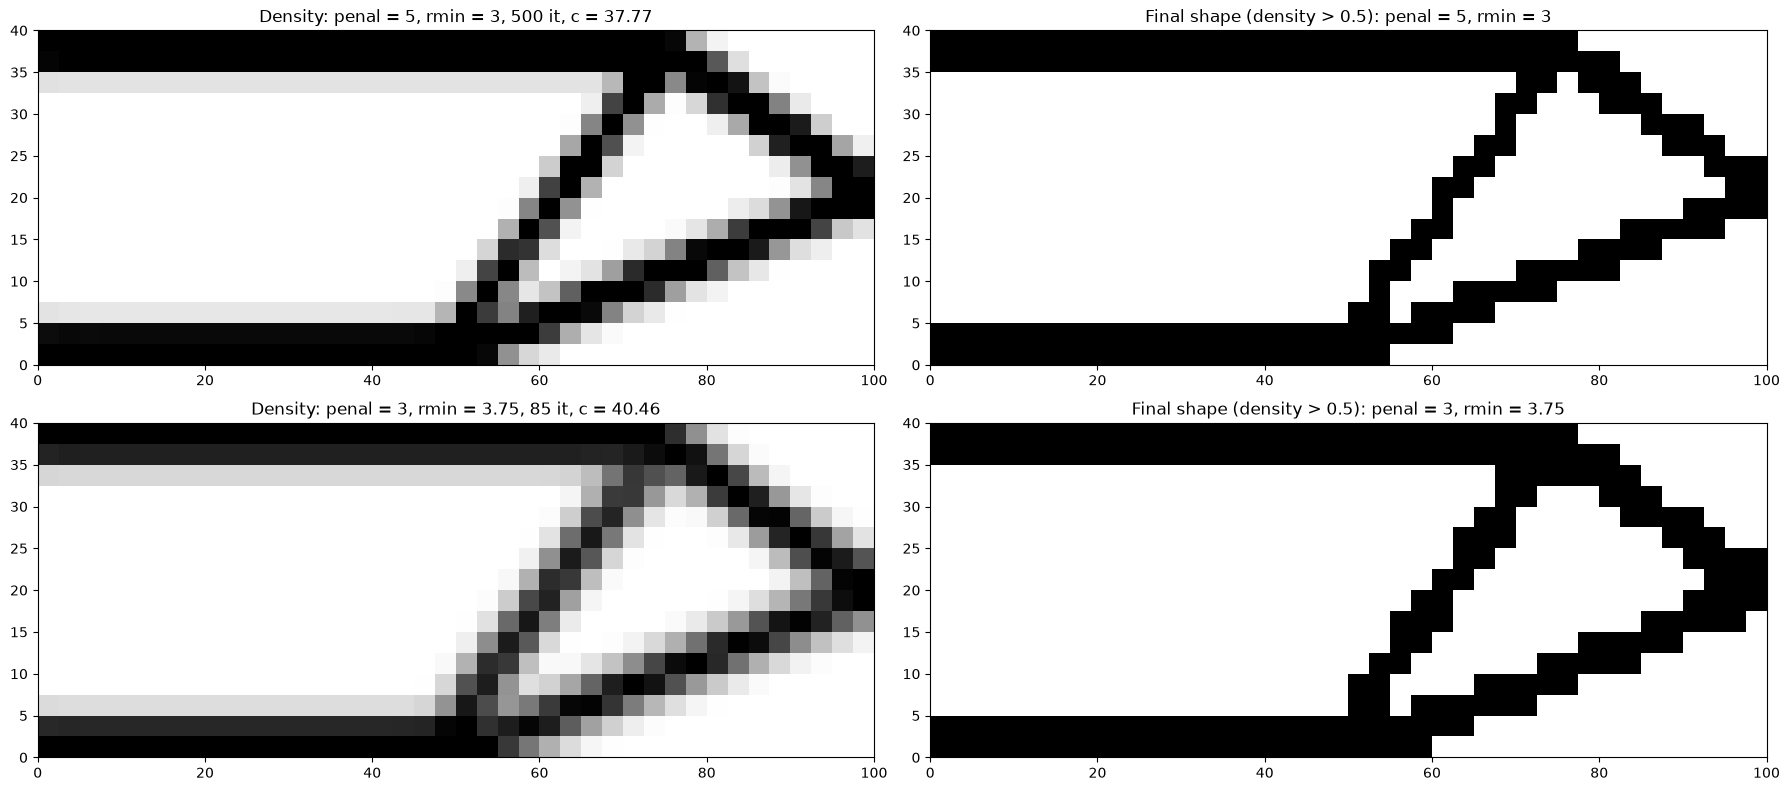

In [16]:
# Left: density result. Right: final design, density > 0.5 = solid (black), else void (white).
fig, axes = plt.subplots(2, 2, figsize=(18, 8))
for row, (p, r) in zip(axes, [(5, 3), (3, 3.75)]):
    x_slab, hist_slab, mesh_slab = run_TO3D(40, 16, 1, 100, 40, 2.5, volfrac=0.3, penal=p, rmin=r,
                                            loop_max=500, print_every=50, bcs=project2_bcs)
    plot_side_view(x_slab, mesh_slab, f"Density: penal = {p}, rmin = {r}, {len(hist_slab['c'])} it, "
                   f"c = {hist_slab['c'][-1]:.2f}", row[0])
    plot_side_view((x_slab > 0.5).astype(float), mesh_slab,
                   f"Final shape (density > 0.5): penal = {p}, rmin = {r}", row[1])
plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR, "test3_slab_project2_bcs.png"), dpi=150)
plt.show()

### Test 4 - True 3D cantilever
60 x 20 x 4 elements (size 1), E = 1, v = 0.25, volfrac = 0.3, **penal = 3**, **rmin = 1.5** (both can be changed below).

Mesh 60 x 20 x 4: 4800 elements, 19215 DOFs


It   1 | c =  1087.5600 | vol = 0.300 | change = 0.2000


It   5 | c =   255.6866 | vol = 0.300 | change = 0.1927


It  10 | c =   179.0208 | vol = 0.300 | change = 0.2000


It  15 | c =   134.7914 | vol = 0.300 | change = 0.1668


It  20 | c =    90.6576 | vol = 0.300 | change = 0.1354


... (2 outputs left out)

It  35 | c =    82.1180 | vol = 0.300 | change = 0.0152


It  40 | c =    82.1105 | vol = 0.300 | change = 0.0119


It  45 | c =    82.1058 | vol = 0.300 | change = 0.0107


converged after 48 iterations, 71.9 s, final c = 82.1089


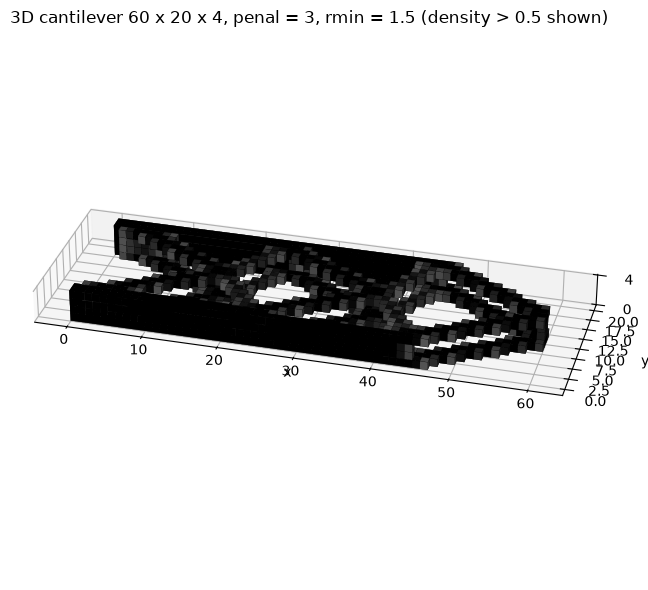

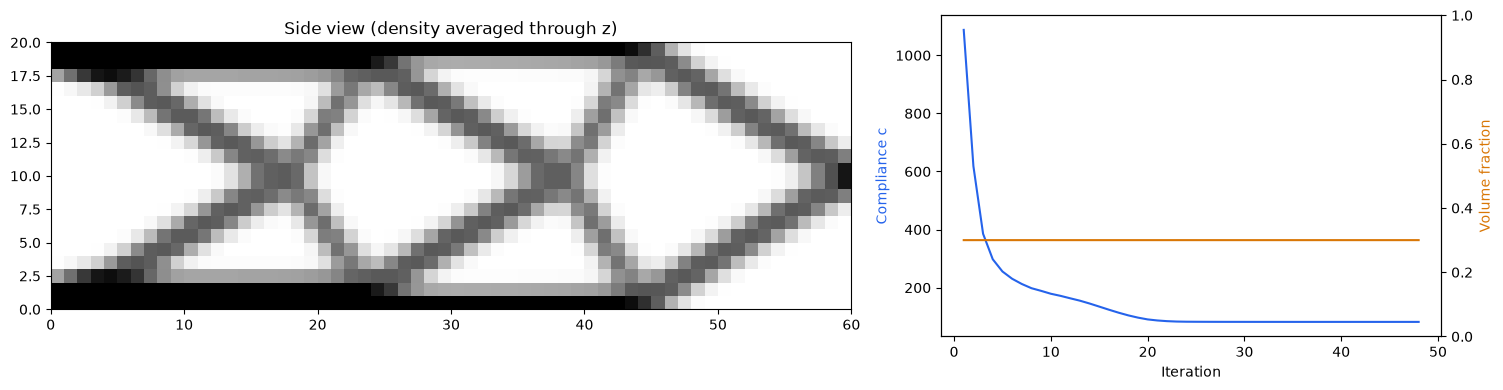

In [17]:
penal = 3      # SIMP penalty
rmin = 1.5     # filter radius (element size = 1)
volfrac = 0.3

x3d, hist3d, mesh3d = run_TO3D(60, 20, 4, 60, 20, 4, volfrac=volfrac, penal=penal, rmin=rmin)

fig = plt.figure(figsize=(12, 6))
ax = fig.add_subplot(projection="3d")
plot_voxels(x3d, mesh3d, threshold=0.5, ax=ax,
            title=f"3D cantilever 60 x 20 x 4, penal = {penal}, rmin = {rmin} (density > 0.5 shown)")
ax.view_init(elev=30, azim=-75)
ax.set_zticks([0, 4])
plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR, "test4_3D_cantilever_3Dview.png"), dpi=150)
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(15, 4), gridspec_kw={"width_ratios": [1.6, 1]})
plot_side_view(x3d, mesh3d, "Side view (density averaged through z)", axes[0])
plot_history(hist3d, axes[1])
plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR, "test4_3D_cantilever_side_history.png"), dpi=150)
plt.show()